# Un balance en 19 bandas de tiempo: la brecha de repreciación, la brecha de duración y un primer EVE

**Pregunta:** un banco con un balance de 211,8 miles de millones de dólares se ubica en las 19 bandas de tiempo estándar; ¿cuánto le cuesta un alza de 100 puntos base en las tasas según la brecha de repreciación de libro de texto, la brecha de duración y un primer valor económico del patrimonio, y cuánto de ese costo descansa en un solo supuesto sobre cuánto tiempo permanecen los depósitos a la vista?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** los notebooks 01 a 04 del tema 01 (el motor, un `TestResult`, las políticas)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook puedes:

- ubicar los flujos de un balance en las 19 bandas de tiempo estándar y decir por qué existen las bandas;
- leer una brecha de repreciación y el efecto de primer orden de un cambio de tasa sobre el margen neto de intereses (NII), y decir qué deja fuera;
- leer una brecha de duración y el efecto de primer orden sobre el valor del patrimonio, y decir qué deja fuera;
- descontar los flujos netos hasta un valor económico del patrimonio (EVE) y explicar por qué el EVE es una medida de valor presente y no contable;
- ver cómo un solo supuesto, el tratamiento de los depósitos a la vista, mueve las tres medidas a la vez.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, slotting

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son la fecha de valoración 2022-06-30 (2022-Q2) del caso C14, el riesgo de tasa de interés en el libro de banca (IRRBB) del banco que quebró en marzo de 2023, tal como Contraste lo versiona. Lo alimentan dos fuentes, ambas de la clase de licencia `mirror-allowed` (`conventions/third-party-datasets.md`):

- los **reportes de condición (call reports) de la FDIC** del banco (estados financieros de FDIC BankFind, https://api.fdic.gov/banks/financials, dominio público), que dan el balance por banda de reprecio;
- la **curva diaria de rendimientos a la par del Tesoro de EE. UU.** (https://home.treasury.gov/resource-center/data-chart-center/interest-rates, dominio público), que da las tasas con que se descuentan los flujos.

El banco es **real en agregado y sintético en comportamiento**: los totales son los del propio banco, pero el reporte no trae comportamiento de depósitos, ni historial de prepagos, ni un perfil más fino que sus bandas, así que todo supuesto de ese tipo lo declara Contraste y queda rotulado como sintético en el documento. El dinero está en miles de USD, las tasas son decimales con capitalización continua, y un delta EVE o delta NII positivo es una **pérdida**.

- **Archivos que se leen:** `data/derived/C14/vd-2022-q2.json` (`outputs.balance_sheet`, `ladder`, `curve`, `scenarios`, `units`, `sign_convention`) y `data/derived/C14/models-svb-2021-2022.json` (las etiquetas bilingües de las 19 bandas).

La celda siguiente carga los dos archivos e imprime lo que el documento dice de sí mismo.

In [2]:
# Leer la fecha de valoración y el documento de modelos del caso C14, y nombrar los dos tratamientos en este idioma
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C14"
doc = json.loads((derived / "vd-2022-q2.json").read_text(encoding="utf-8"))
models = json.loads((derived / "models-svb-2021-2022.json").read_text(encoding="utf-8"))
out = doc["outputs"]
items = out["balance_sheet"]["items"]
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
NAME = {"behavioural": "conductual", "contractual": "contractual"}
print(out["bank"]["name"], "|", out["valuation_date"], "|", out["currency"], "| miles de USD")
print(out["bank"]["notice"][LANG])
print(out["sign_convention"]["statement"][LANG])

Silicon Valley Bank | 2022-06-30 | USD | miles de USD
Los agregados del reporte son los del banco, leídos de los estados financieros de FDIC BankFind. Todo supuesto de comportamiento (proporción y plazo estables de los depósitos, prepago, rescate de depósitos a plazo, la distribución de las bandas del reporte) es sintético y está declarado en el documento.
Un delta EVE o delta NII positivo es una pérdida; solo las pérdidas se agregan entre monedas.


## Método

El método tiene cinco pasos: (1) las 19 bandas, (2) ubicar flujos en ellas, (3) la brecha de repreciación y su efecto de primer orden sobre el NII, (4) la brecha de duración, (5) el EVE. Cada número es una llamada al motor; el notebook arma los insumos desde el documento versionado y dibuja lo que el motor devuelve.

### Paso 1: las 19 bandas de tiempo

El marco estandarizado del Comité de Basilea ubica todo flujo sensible a la tasa de interés en 19 bandas de tiempo, desde a la vista hasta más de 20 años, y representa cada banda por su punto medio (BCBS, SRP31.96, Tabla 3, https://www.bis.org/basel_framework/chapter/SRP/31.htm). Una banda es un intervalo $(\text{inferior}, \text{superior}]$: un flujo exactamente a un mes cae en la primera banda que termina en un mes. La función `bucket_grid` del motor devuelve los bordes, los puntos medios y las etiquetas. La celda siguiente imprime siete de las diecinueve bandas.

In [3]:
# La grilla de 19 bandas del motor: los bordes y el punto medio de cada banda, en años
grid = slotting.bucket_grid()
MID = grid.midpoints
print(f"{'banda':>6s} {'inferior (a)':>14s} {'superior (a)':>14s} {'medio (a)':>14s}")
for k in (0, 1, 2, 5, 9, 14, 18):
    print(f"{k + 1:6d} {grid.lower[k]:14.4f} {grid.upper[k]:14.4f} {MID[k]:14.4f}")
print("bandas:", len(MID))

 banda   inferior (a)   superior (a)      medio (a)
     1         0.0000         0.0028         0.0028
     2         0.0028         0.0833         0.0417
     3         0.0833         0.2500         0.1667
     6         0.7500         1.0000         0.8750
    10         3.0000         4.0000         3.5000
    15         8.0000         9.0000         8.5000
    19        20.0000            inf        25.0000
bandas: 19


### Paso 2: ubicar los flujos en las bandas

`bucket_of` da el número de banda de un plazo y `slot_cash_flows` suma una lista de montos en plazos dados dentro de las 19 bandas (activos positivos, pasivos negativos); la suma del resultado es igual a la suma de los montos, así que ubicar mueve dinero entre bandas y nunca lo crea ni lo destruye. La celda siguiente ubica un ejemplo pequeño con plazos elegidos a mano: un préstamo bullet de 1.000 que vence en 5 años, un depósito de 400 que reprecia en 2,3 años y un depósito de 300 que reprecia exactamente en un mes.

In [4]:
# Ubicar tres flujos a mano: la banda de cada plazo y el vector de 19 bandas que forman
times = np.array([5.0, 2.3, 1 / 12])
amounts = np.array([1000.0, -400.0, -300.0])
bands = [slotting.bucket_of(t, grid) for t in times]
slotted = slotting.slot_cash_flows(times, amounts, grid)
print("banda de cada flujo:", bands)
print("bandas con monto:", {k + 1: float(v) for k, v in enumerate(slotted) if v != 0.0})
print("suma de los flujos ubicados:", float(slotted.sum()), "| suma de los montos:", float(amounts.sum()))

banda de cada flujo: [11, 9, 2]
bandas con monto: {2: -300.0, 9: -400.0, 11: 1000.0}
suma de los flujos ubicados: 300.0 | suma de los montos: 300.0


### El balance versionado

El balance del banco tiene 17 partidas (8 activos y 9 pasivos). El proceso del producto ubicó cada una en las 19 bandas con el motor y versionó el resultado dos veces: con el tratamiento **conductual** de los depósitos a la vista (la parte que el estándar llama estable se reparte en el tiempo, con los topes del estándar) y con el tratamiento **contractual** (todo depósito a la vista a un día). La celda siguiente dibuja las partidas, activos a la izquierda y pasivos a la derecha, e imprime los dos totales y el patrimonio que muestran los libros.

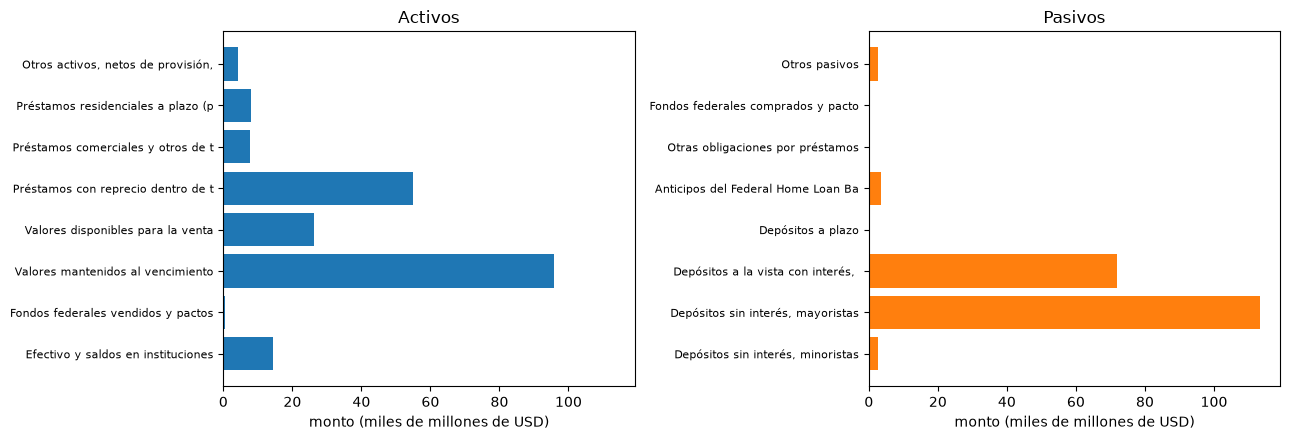

total de activos: 211,824,000 | total de pasivos: 196,438,000
patrimonio contable: 15,386,000


In [5]:
# Dibujar las 17 partidas, activos a la izquierda y pasivos a la derecha, e imprimir los totales de los libros
side = {s: [it for it in items if it["side"] == s] for s in ("asset", "liability")}
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
panels = ((left, "asset", "tab:blue", "Activos"), (right, "liability", "tab:orange", "Pasivos"))
for ax, key, colour, title in panels:
    ax.barh([it["label"][LANG][:34] for it in side[key]], [it["amount"] / 1e6 for it in side[key]], color=colour)
    ax.set_title(title)
    ax.set_xlabel("monto (miles de millones de USD)")
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()
assets = sum(it["amount"] for it in side["asset"])
liabilities = sum(it["amount"] for it in side["liability"])
print(f"total de activos: {assets:,.0f} | total de pasivos: {liabilities:,.0f}")
print(f"patrimonio contable: {assets - liabilities:,.0f}")

Los dos paneles muestran dónde está el dinero del banco. Del lado de los activos, los valores mantenidos hasta el vencimiento superan a todo lo demás, unos 95,8 miles de millones de dólares de papel largo a tasa fija, con los préstamos que reprecian dentro de tres meses y los valores disponibles para la venta detrás; del lado de los pasivos, los depósitos son las barras grandes. La imagen no dice cuándo reprecia cada partida, solo cuán grande es: el momento lo fijan las 19 bandas, que el paso siguiente construye para los dos tratamientos de los depósitos. De los totales se sigue que los libros muestran un patrimonio pequeño, un 7 por ciento de los activos, contra el cual hay que leer cualquier medida de riesgo de tasa.

### Paso 3: la brecha de repreciación y el efecto de primer orden sobre el NII

El vector de 19 bandas de cada partida está en `cash_flows`. La celda siguiente arma los vectores de los activos y de los pasivos bajo cada tratamiento (los pasivos se guardan con monto negativo y las funciones de brecha reciben magnitudes, así que el vector de pasivos es el negativo de la suma guardada) y pide al motor la brecha de repreciación de cada uno.

La brecha de repreciación de la banda $k$ son los activos menos los pasivos que reprecian en ella, $G_k = RSA_k - RSL_k$, en dinero. Para un cambio paralelo $\Delta r$ y un horizonte de un año con balance constante, la aproximación de libro de texto del cambio en el NII por brechas es

$$\Delta NII \approx \sum_{t_k < 1} G_k \,\Delta r\, (1 - t_k)$$

donde $t_k$ es el punto medio de la banda $k$ en años: una brecha que reprecia temprano gana la nueva tasa el resto del año. Ignora el riesgo de base, las opciones y el negocio nuevo (fuente: dossier 05, D.1, y la literatura de brechas de ganancias; BCBS exige la sensibilidad del NII bajo los dos escenarios paralelos para la divulgación, d368). La función `delta_nii_gap` del motor lo informa **con la pérdida positiva**, así que una brecha positiva gana más cuando suben las tasas y devuelve un número negativo.

In [6]:
# Armar los vectores de 19 bandas de activos y pasivos bajo cada tratamiento y tomar sus brechas de reprecio
flows, gaps = {}, {}
for treatment in ("behavioural", "contractual"):
    vec = {"asset": np.zeros(19), "liability": np.zeros(19)}
    for it in items:
        for row in it["cash_flows"][treatment]:
            vec[it["side"]][row["bucket"] - 1] += row["amount"]
    flows[treatment] = (vec["asset"], -vec["liability"])
    gaps[treatment] = eve_nii.repricing_gap(*flows[treatment])
    top = int(np.argmax(np.abs(gaps[treatment])))
    print(f"{NAME[treatment]:12s} mayor brecha {gaps[treatment][top]:16,.0f} en la banda {top + 1}")

conductual   mayor brecha      -76,433,446 en la banda 1
contractual  mayor brecha     -172,807,898 en la banda 1


Las brechas están a mano. La celda siguiente pide al motor el cambio de primer orden del NII para +100 pb bajo cada tratamiento, separa el conductual por banda bajo un año, y dibuja la escalera de reprecio junto a esa separación.

conductual   delta NII para +100 pb (pérdida positiva):      199,057
contractual  delta NII para +100 pb (pérdida positiva):    1,199,488
suma de las contribuciones: 199057 | delta NII del motor: 199057


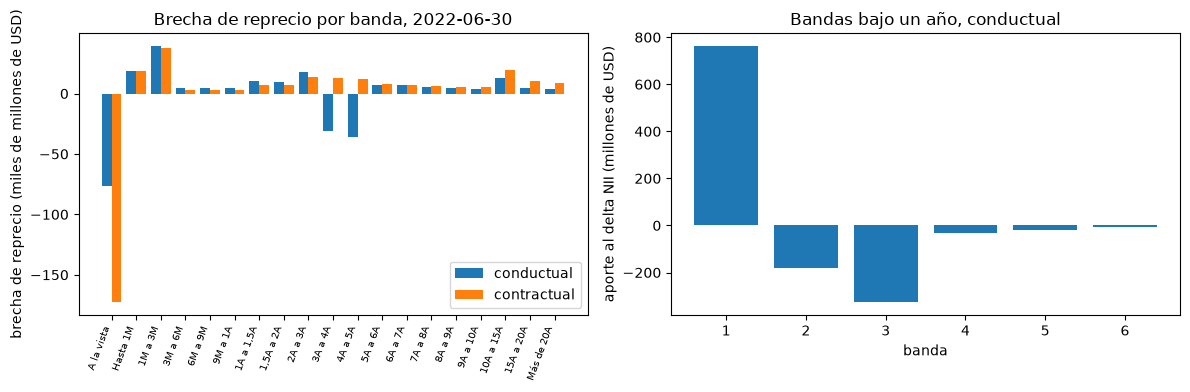

In [7]:
# El cambio de primer orden del NII para +100 pb bajo cada tratamiento, y el aporte de cada banda bajo un año
gap = gaps["behavioural"]
near = MID < 1.0
contribution = -gap[near] * 0.01 * (1.0 - MID[near])
for treatment in ("behavioural", "contractual"):
    d_nii = eve_nii.delta_nii_gap(gaps[treatment], MID, 100.0)
    print(f"{NAME[treatment]:12s} delta NII para +100 pb (pérdida positiva): {d_nii:12,.0f}")
engine_value = eve_nii.delta_nii_gap(gap, MID, 100.0)
print("suma de las contribuciones:", round(float(contribution.sum())), "| delta NII del motor:", round(engine_value))
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(19)
left.bar(x - 0.2, gaps["behavioural"] / 1e6, 0.4, label=NAME["behavioural"])
left.bar(x + 0.2, gaps["contractual"] / 1e6, 0.4, label=NAME["contractual"])
left.set_xticks(x)
names = [b["label"][LANG] for b in models["fit"]["buckets"]]
left.set_xticklabels(names, rotation=70, ha="right", fontsize=7)
left.set_ylabel("brecha de reprecio (miles de millones de USD)")
left.set_title("Brecha de reprecio por banda, 2022-06-30")
left.legend()
right.bar(np.arange(1, near.sum() + 1), contribution / 1e3)
right.set_xlabel("banda")
right.set_ylabel("aporte al delta NII (millones de USD)")
right.set_title("Bandas bajo un año, conductual")
fig.tight_layout()
plt.show()

El panel izquierdo es la escalera de reprecio. Con el tratamiento conductual la banda a la vista tiene una gran brecha negativa, los depósitos que reprecian de inmediato, y las bandas de un mes a un año tienen brechas positivas de activos que reprecian pronto; con el tratamiento contractual todo depósito a la vista está a un día, así que la brecha a la vista es más del doble de negativa. El panel derecho separa el delta NII conductual en sus bandas bajo un año: la banda a la vista es una pérdida porque su peso $1 - t_k$ es casi uno, y las otras cinco devuelven ganancias que dejan el neto en el número pequeño impreso arriba. De ahí se sigue que el neto es una diferencia de números mayores, así que un validador lee la escalera completa y no solo su suma. La imagen no muestra opciones, riesgo de base ni negocio nuevo, que la aproximación deja fuera.

### Paso 4: la brecha de duración y el efecto de primer orden sobre el patrimonio

La brecha de duración compara cuánto tardan los activos y los pasivos, ponderados por valor, en pagarse en valor presente. Con el valor presente de los activos $A$ y de los pasivos $L$, y sus duraciones ponderadas por valor $D_A$ y $D_L$,

$$DGAP = D_A - \frac{L}{A}\, D_L, \qquad \Delta E \approx -DGAP \cdot A \cdot \Delta y$$

(fuente: dossier 05, D.2: una aproximación de primer orden de libro de texto sin una única fuente primaria). Con capitalización continua la duración modificada es igual a la de Macaulay, el tiempo promedio ponderado por valor. Una brecha positiva significa que los activos son más largos que los pasivos, así que una suba de tasas baja el patrimonio. La función `duration_gap` del motor necesita los flujos, las tasas cero en los puntos medios y los puntos medios; primero hacen falta las tasas.

#### La curva cero

El Tesoro publica **rendimientos a la par** en 12 plazos; descontar necesita **tasas cero**. La función `bootstrap_zero_curve` del motor convierte los rendimientos a la par en tasas cero con capitalización continua (cupones semestrales de equivalente bono, interés simple hasta seis meses), y `zero_rates_at` las interpola linealmente en el plazo, planas fuera de la grilla, en los 19 puntos medios. `discount_factors` convierte esas tasas en $DF_k = \exp(-R_k t_k)$. La celda siguiente hace los tres pasos desde los rendimientos observados y los dibuja.

tipo de curva: par-yield | plazos: 12
plazo faltante (años): [0.333333]
factores de descuento en las bandas 1, 10 y 19: [0.999964, 0.901054, 0.442993]


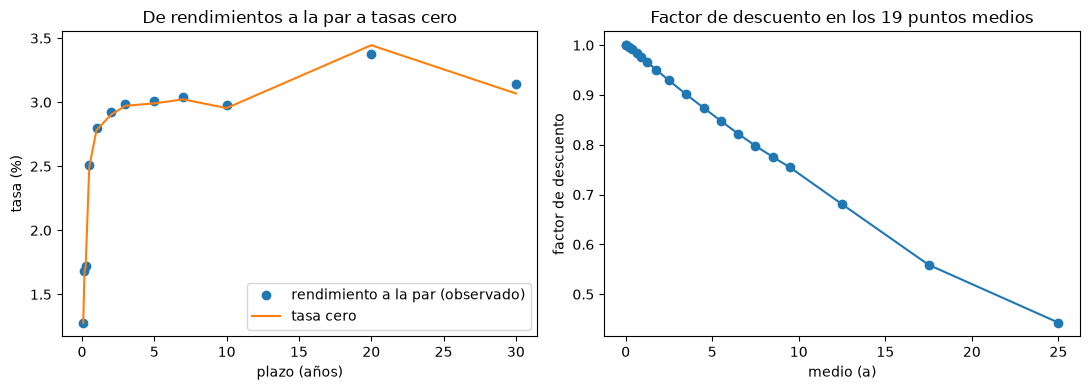

In [8]:
# Construir la curva cero desde los rendimientos a la par observados, leerla en los 19 puntos medios y descontar
points = out["curve"]["points"]
tenors = np.array([p["tenor_years"] for p in points])
par = np.array([p["observed_yield"] for p in points])
zero = curves.bootstrap_zero_curve(tenors, par, 2)
r0 = curves.zero_rates_at(tenors, zero, MID)
df = curves.discount_factors(r0, MID)
print("tipo de curva:", out["curve"]["observed_kind"], "| plazos:", len(tenors))
print("plazo faltante (años):", out["curve"]["missing_tenors"])
print("factores de descuento en las bandas 1, 10 y 19:", [round(float(df[k]), 6) for k in (0, 9, 18)])
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.plot(tenors, par * 100, "o", label="rendimiento a la par (observado)")
left.plot(tenors, zero * 100, label="tasa cero")
left.set_xlabel("plazo (años)")
left.set_ylabel("tasa (%)")
left.set_title("De rendimientos a la par a tasas cero")
left.legend()
right.plot(MID, df, marker="o")
right.set_xlabel("medio (a)")
right.set_ylabel("factor de descuento")
right.set_title("Factor de descuento en los 19 puntos medios")
fig.tight_layout()
plt.show()

El panel izquierdo muestra qué cambia la construcción de la curva cero: las tasas cero quedan un poco bajo los rendimientos a la par en casi todos los plazos, porque el mismo retorno escrito con capitalización continua es un número algo menor que la convención de cupón semestral del rendimiento a la par, y la diferencia se abre a 20 años, donde el rendimiento a la par de 3,38 por ciento pasa a una tasa cero de 3,45 por ciento. La curva sube de 1,3 por ciento a un mes a 3,0 por ciento a tres años, y luego es plana. El plazo de 4 meses falta en la serie del Tesoro ese día y la curva se arma con los 12 plazos que existen. El panel derecho es la consecuencia para los flujos: un flujo de la última banda, a 25 años, vale 44 centavos por dólar, y uno de la primera banda casi un dólar entero. La imagen muestra un solo día, 2022-06-30, cuando la curva tenía pendiente positiva y el descuento de los activos largos era suave; el mismo balance otro día tiene otros factores de descuento.

#### La brecha de duración sobre el balance real

Ahora la brecha de duración, para el tratamiento conductual y para el contractual. Los dos tratamientos difieren en los pasivos: con todo depósito a la vista a un día, los pasivos casi no tienen duración y los activos son mucho más largos, así que la brecha es grande. La celda siguiente pide al motor la brecha e imprime los valores presentes y las duraciones.

In [9]:
# La brecha de duración del balance bajo cada tratamiento y el cambio de primer orden del patrimonio para +100 pb
dgap = {}
for treatment, (a, l) in flows.items():
    dg = eve_nii.duration_gap(a, l, r0, MID)
    dgap[treatment] = dg
    print(NAME[treatment])
    print(f"  VP de activos {dg.asset_value:14,.0f} | VP de pasivos {dg.liability_value:14,.0f}")
    print(f"  duración de activos (a) {dg.asset_duration_years:7.4f}")
    print(f"  duración de pasivos (a) {dg.liability_duration_years:7.4f}")
    print(f"  brecha de duración (a) {dg.duration_gap_years:7.4f}")
    print(f"  cambio del patrimonio para +100 pb {dg.equity_change_100bp_up:14,.0f}")

conductual
  VP de activos    192,515,579 | VP de pasivos    185,478,799
  duración de activos (a)  2.8407
  duración de pasivos (a)  1.8656
  brecha de duración (a)  1.0433
  cambio del patrimonio para +100 pb     -2,008,492
contractual
  VP de activos    185,093,900 | VP de pasivos    196,381,326
  duración de activos (a)  3.8215
  duración de pasivos (a)  0.0128
  brecha de duración (a)  3.8079
  cambio del patrimonio para +100 pb     -7,048,257


### Paso 5: el valor económico del patrimonio

El EVE es el valor presente de los flujos netos: los activos menos los pasivos, cada uno descontado a su tasa cero. Con los flujos netos $CF_k$ (activos positivos, pasivos negativos) y las tasas cero $R_k$ en los puntos medios (BCBS SRP31.129; dossier 05, D.2):

$$DF_k = \exp(-R_k\, t_k), \qquad EVE = \sum_{k=1}^{19} CF_k \, DF_k$$

Es una medida de **valor presente**: pregunta cuánto vale hoy el balance si cada flujo se paga como se ubicó, no lo que dicen los libros. Por eso puede estar lejos del patrimonio contable, y por eso el tratamiento de los depósitos, que los libros llevan a la par, lo mueve tanto. La celda siguiente pide al motor el EVE de cada tratamiento con `eve` y lo dibuja junto al patrimonio de los libros.

conductual   EVE      7,036,780
contractual  EVE    -11,287,425
patrimonio contable: 15,386,000


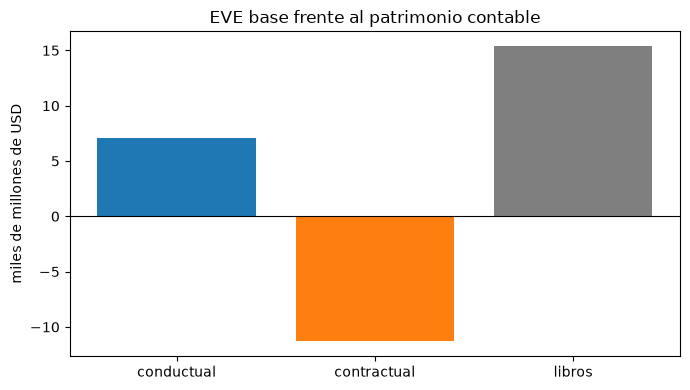

In [10]:
# El EVE de cada tratamiento desde los flujos netos y la curva cero, dibujado junto al patrimonio de los libros
base = {t: eve_nii.eve(a - l, r0, MID) for t, (a, l) in flows.items()}
for treatment, value in base.items():
    print(f"{NAME[treatment]:12s} EVE {value:14,.0f}")
print(f"patrimonio contable: {assets - liabilities:,.0f}")
labels = [NAME["behavioural"], NAME["contractual"], "libros"]
values = [base["behavioural"], base["contractual"], assets - liabilities]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(labels, [v / 1e6 for v in values], color=["tab:blue", "tab:orange", "tab:grey"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("miles de millones de USD")
ax.set_title("EVE base frente al patrimonio contable")
fig.tight_layout()
plt.show()

Las tres barras son el mismo banco. Los libros muestran un patrimonio positivo de 15,4 miles de millones de dólares; el EVE con el tratamiento conductual es menos de la mitad, y con todo depósito a la vista a un día el EVE es negativo: en esa lectura el banco vale menos que sus pasivos, 26,7 miles de millones de dólares bajo los libros. Toda la distancia entre las dos barras de EVE viene de un supuesto, cuánto tiempo permanecen los depósitos a la vista, y ningún número del reporte de condición lo decide. Lo que la imagen no muestra es si el supuesto conductual es correcto: aquí es sintético, y el notebook 03 lo desarma.

## Resultados

**Respuesta:** las medidas de libro de texto ponen el costo de un alza de 100 puntos base en un número pequeño o grande según un supuesto. Con el tratamiento conductual la brecha de repreciación da una pérdida de NII de 199.057 (miles de USD), la brecha de duración es 1,0433 años, el cambio de primer orden del patrimonio es -2.008.492 y el EVE es 7.036.780; con todo depósito a la vista a un día la pérdida de NII es 1.199.488, la brecha de duración 3,8079 años, el cambio del patrimonio -7.048.257 y el EVE -11.287.425, frente a 15.386.000 de patrimonio en los libros.

- **Ubicación.** El ejemplo de tres flujos cae en las bandas 11, 9 y 2, y su total, 300, no cambia: ubicar mueve dinero entre bandas y nunca lo crea. En el banco, 211.824.000 de activos y 196.438.000 de pasivos (miles de USD) están en los libros, y ambos tratamientos los ubican todos en las bandas; el tratamiento cambia dónde están los pasivos, nunca cuánto hay.
- **Brecha de repreciación y NII.** La mayor brecha es -76.433.446 en la banda a la vista con el tratamiento conductual y -172.807.898 con el contractual. La banda a la vista aporta una pérdida de 762.194 y las otras cinco bandas bajo un año devuelven unos 563.000, así que el neto de 199.057 es la diferencia de números mayores: un validador lee la escalera completa, no solo su suma. La aproximación mantiene constante el balance, usa un mismo desplazamiento para todas las bandas e ignora las opciones.
- **Brecha de duración.** La brecha conductual de 1,0433 años se lleva el 13 por ciento del patrimonio contable por +100 pb; la contractual de 3,8079 años se lleva el 46 por ciento. Ambos números son de primer orden: dicen hacia dónde y aproximadamente cuánto, no cuánto exactamente, y no pueden ver los pisos, las opciones ni un choque no paralelo.
- **EVE.** El EVE es un valor presente de los flujos tal como se ubicaron, por eso difiere del patrimonio contable, y toda la distancia entre los dos EVE viene de un supuesto, cuánto tiempo permanecen los depósitos a la vista. El notebook 03 desarma ese supuesto.
- **Lo que el notebook no muestra.** Los seis choques del estándar (notebook 02) y los supuestos de comportamiento detrás de la parte estable de los depósitos (notebook 03).

## Resumen

- Un balance se vuelve 19 números por lado: ubicar mueve cada flujo a la banda de su plazo de reprecio o vencimiento y nunca cambia el total.
- La brecha de repreciación es activos menos pasivos por banda; su efecto de primer orden sobre el NII conserva solo las bandas bajo un año, ponderadas por el tiempo que queda del año.
- La brecha de duración es la diferencia entre las duraciones ponderadas por valor de activos y pasivos, escalada por el apalancamiento; da el efecto de primer orden sobre el patrimonio.
- El EVE es un valor presente, y el tratamiento de los depósitos a la vista lo mueve más que el patrimonio de los libros.
- Las dos aproximaciones son de primer orden e ignoran opciones y riesgo de base; los notebooks siguientes las reemplazan por los seis choques del estándar y por la capa de comportamiento.

**Qué probar a continuación.** Cambia el desplazamiento de +100 pb de `delta_nii_gap` por -100 pb y lee el signo. Después sigue con el notebook 02, los seis choques estándar.

## Referencias

- BCBS, Standards: Interest rate risk in the banking book, SRP31, Tabla 3 (las 19 bandas de tiempo) y SRP31.129 (el EVE estandarizado). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book. https://www.bis.org/bcbs/publ/d368.htm
- FDIC, BankFind financials (reportes de condición), dominio público. https://api.fdic.gov/banks/financials
- Departamento del Tesoro de EE. UU., Daily Treasury Par Yield Curve Rates, dominio público. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 de la investigación de Contraste (modelos de IRRBB y ALM), secciones D.1 y D.2: las aproximaciones por brechas de ganancias y de duración.